# Importing Libraries

In [1]:
# ===============================
# Core Python Libraries
# ===============================
import os
import pickle
import joblib
import numpy as np
import pandas as pd
from collections import Counter
from scipy.special import expit  # sigmoid

# ===============================
# Data Visualization
# ===============================
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from PIL import Image, ImageTk
import cv2
# ===============================
# System & Utilities
# ===============================
import os
import joblib
import numpy as np
from tqdm import tqdm
import re

# ===============================
# NLP: NLTK 
# ===============================
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.util import ngrams

In [2]:
# ===============================
# Scikit-learn: Preprocessing, Models, Metrics
# ===============================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import joblib, os
from sklearn.linear_model import SGDClassifier, PassiveAggressiveClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from imodels import GreedyTreeClassifier
from sklearn.model_selection import train_test_split
# ===============================
# TensorFlow / Keras
# ===============================
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Dense, Input, Embedding, Conv1D, GlobalMaxPooling1D, LSTM, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# ===============================
# Transformers (Hugging Face)
# ===============================
import torch
# ===============================
# Custom Modules
# ===============================
from metrics_calculator import MetricsCalculator
from graphs import GraphPlotter
from transformers import (
    AutoTokenizer, AutoModel,
    RobertaTokenizer, RobertaModel,
    BertTokenizer, BertForSequenceClassification,
    XLNetTokenizer, XLNetForSequenceClassification
)
# ===============================
# Model Directory
# ===============================

<frozen importlib._bootstrap>:488: DeprecationWarning: Type google._upb._message.MessageMapContainer uses PyType_Spec with a metaclass that has custom tp_new. This is deprecated and will no longer be allowed in Python 3.14.
<frozen importlib._bootstrap>:488: DeprecationWarning: Type google._upb._message.ScalarMapContainer uses PyType_Spec with a metaclass that has custom tp_new. This is deprecated and will no longer be allowed in Python 3.14.
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute


In [3]:
# NLTK Downloads
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
from tqdm import tqdm
tqdm.pandas()

In [4]:
MODEL_DIR = "DNN_model"
os.makedirs(MODEL_DIR, exist_ok=True)

# Dataset Reading

In [5]:
def upload_dataset():
    global file_path,df
    df = pd.read_csv(file_path)

In [6]:
file_path = r"C:\Users\ADVAITHA-AI\Desktop\Cyber insurance code\Dataset\Dataset.csv"
upload_dataset()

In [7]:
df

,ID,year,Actor,victim.victim_id,org_size,victim.industry.name,pattern,summary
0,137,2015,External,American Tooling Center,11 - 100,Manufacturing,Social.Engineering,a federal appeals court has sided with a comme...
1,158,2015,External,Ubiquiti Networks Inc.,101 - 1000,Professional,Social.Engineering,"Ubiquiti Networks Inc., the San Jose based man..."
2,88,2013,External,University of Mississippi Medical Center,"1,001 - 10,000",Healthcare,Lost.and.Stolen.Assets,The University of Mississippi Medical Center i...
3,94,2013,Internal,Wells Fargo,"Over 100,000",Finance,Privilege.Misuse,former fire captain accessed the account of a ...
4,177,2016,External,Platte County Assessor Office,11 - 100,Public,Social.Engineering,transferred money on spoofed email from CEO
...,...,...,...,...,...,...,...,...
115,2,2010,External,Scottrade,Unknown,Finance,Basic.Web.Application.Attacks,Hackers gained unauthorized access to trading ...
116,120,2014,External,The Home Depot,"Over 100,000",Retail,System.Intrusion,"The Home Depot, the world's largest home impro..."
117,72,2013,Internal,Jumbo Chinese Buffet,Unknown,Accomodation,Everything.Else,A man who waited tables at a Hazle Township re...
118,155,2015,External,Scottrade,"1,001 - 10,000",Finance,Basic.Web.Application.Attacks,"Law enforcement officials contacted Scottrade,..."


In [8]:
target_cols = ["pattern","Actor"]


# Dataset Preprocessing

In [9]:
def preprocess_data(df, save_path=None, target_cols=None):

    global label_encoders
    label_encoders = {}  # dictionary to hold encoders for each target column

    if save_path and os.path.exists(save_path):
        print(f"Loading existing preprocessed file: {save_path}")
        df = pd.read_csv(save_path)
    else:
        print("Preprocessing data" + (f" and saving to: {save_path}" if save_path else " (no saving)"))
        lemmatizer = WordNetLemmatizer()
        stop_words = set(stopwords.words('english'))

        def clean_text(text):
            text = str(text).lower()
            tokens = word_tokenize(text)
            tokens = [lemmatizer.lemmatize(t) for t in tokens if t.isalnum() and t not in stop_words]
            return ' '.join(tokens)

        # Separate target columns
        target_df = None
        if target_cols:
            existing_targets = [col for col in target_cols if col in df.columns]
            target_df = df[existing_targets].copy()
            df = df.drop(columns=existing_targets)

        # Process text columns
#        text_columns = df.select_dtypes(include='object').columns
 #       for col in text_columns:
  #          df[f'processed_{col}'] = df[col].apply(clean_text)

        text_columns = df.select_dtypes(include='object').columns
        for col in tqdm(text_columns,
                        desc="Processing Text Columns",
                        unit="column"):
            
            df[f'processed_{col}'] = df[col].progress_apply(clean_text)
            
        # Drop original text columns
        df.drop(columns=text_columns, inplace=True)

        # Reattach target columns
        if target_df is not None:
            for col in target_df.columns:
                df[col] = target_df[col]

        # Save only if path is specified
        if save_path:
            df.to_csv(save_path, index=False)

    # Select processed and numerical columns
    processed_text_cols = [col for col in df.columns if col.startswith('processed_')]
    non_text_cols = [col for col in df.columns if col not in processed_text_cols + (target_cols if target_cols else [])]

    # Join processed text columns into one string
    X_text = df[processed_text_cols].astype(str).agg(' '.join, axis=1)

    # Combine with numerical columns if any
    X_numeric = df[non_text_cols].values if non_text_cols else None
    if X_numeric is not None and len(X_numeric) > 0:
        X = [f"{text} {' '.join(map(str, numeric))}" for text, numeric in zip(X_text, X_numeric)]
    else:
        X = X_text.tolist()

    # Encode multiple target columns
    Y_dict = {}
    if target_cols:
        for col in target_cols:
            if col in df.columns:
                le = LabelEncoder()
                Y_dict[col] = le.fit_transform(df[col])
                label_encoders[col] = le

    return X, Y_dict

In [10]:
def plot_target_distributions(Y_dict):

    # Convert to DataFrame
    y_df = pd.DataFrame(Y_dict)

    # Loop through each target column
    for col in y_df.columns:

        # Print total number of rows
        total_rows = len(y_df[col])
        print(f"{col} → Total Rows: {total_rows}")

        # Plot count distribution
        plt.figure(figsize=(6, 4))
        ax = sns.countplot(x=y_df[col])

        # Add count labels on each bar
        for p in ax.patches:
            height = p.get_height()
            ax.annotate(
                f'{height}',                     # text
                (p.get_x() + p.get_width()/2, height),  # position
                ha='center', va='bottom', 
                fontsize=10, fontweight='bold'
            )

        plt.title(f'Class Distribution: {col}')
        plt.xlabel('Class')
        plt.ylabel('Count')
        plt.tight_layout()
        plt.show()

In [11]:
def Preprocess_Dataset_button():
    global df, X, Y_dict
    global metrics_calculator_dict, target_cols

    X, Y_dict = preprocess_data(
        df,
        save_path=f"{MODEL_DIR}/cleaned_data.csv",
        target_cols=target_cols
    )

    metrics_calculator_dict = {}

    print("Extracted Label Classes:\n")

    for col, le in label_encoders.items():

        labels = list(le.classes_)  # class names list

        # Print readable summary
        print(f"Target: {col}")
        for idx, class_name in enumerate(labels):
            print(f"  {idx}: {class_name}")
        print()

        # Save labels
        label_file = os.path.join(MODEL_DIR, f"labels_{col}.npy")
        np.save(label_file, np.array(labels), allow_pickle=True)

        # Create metrics calculator
        metrics_calculator_dict[col] = MetricsCalculator(
            labels,
            text_widget=None
        )

    print("Labels saved successfully!\n")

    # Plot distributions

In [12]:
Preprocess_Dataset_button()

Loading existing preprocessed file: DNN_model/cleaned_data.csv
Extracted Label Classes:

Target: pattern
  0: Basic.Web.Application.Attacks
  1: Everything.Else
  2: Lost.and.Stolen.Assets
  3: Miscellaneous.Errors
  4: Privilege.Misuse
  5: Social.Engineering
  6: System.Intrusion

Target: Actor
  0: External
  1: Internal
  2: Multiple
  3: Partner

Labels saved successfully!



pattern → Total Rows: 120


C:\Envs\py3120env\Lib\site-packages\seaborn\categorical.py:1281: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


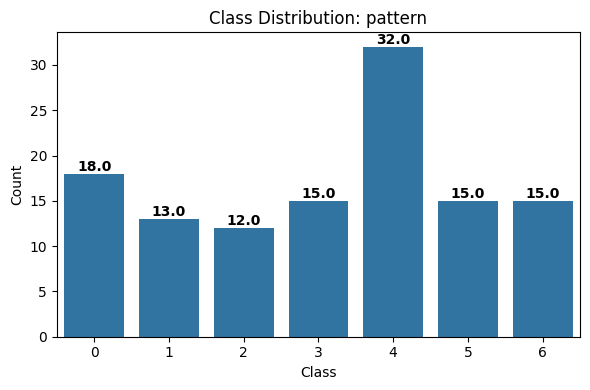

Actor → Total Rows: 120


C:\Envs\py3120env\Lib\site-packages\seaborn\categorical.py:1281: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


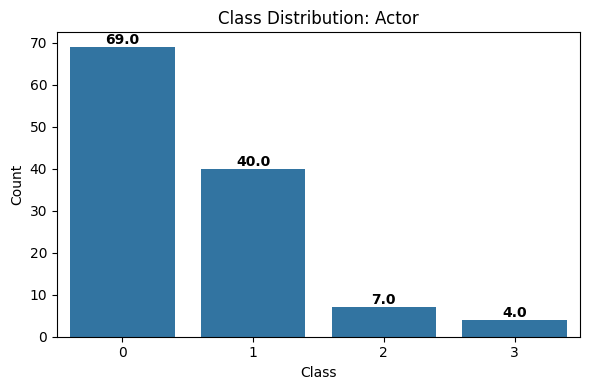

In [13]:
plot_target_distributions(Y_dict)

# EDA

In [14]:
def eda_nlp_analysis():
    global df,X, Y_dict

    X_text = X
    num_words=100
    top_n_words=20
    
    print("Generating NLP EDA Visualizations..."+"\n\n")

    # Flatten all tokens from all texts
    all_tokens = [word for doc in X_text for word in word_tokenize(doc)]

    # --- 1. WordCloud ---
    word_freq = Counter(all_tokens)
    wc = WordCloud(width=800, height=400, max_words=num_words, background_color='white').generate_from_frequencies(word_freq)

    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Top {num_words} Words - WordCloud")
    plt.show()

    # --- 2. Top-N Frequent Words ---
    common_words = word_freq.most_common(top_n_words)
    words, counts = zip(*common_words)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title(f"Top {top_n_words} Most Frequent Words")
    plt.xlabel("Count")
    plt.ylabel("Word")
    plt.show()

    # --- 3. Document Length Histogram ---
    doc_lengths = [len(word_tokenize(doc)) for doc in X_text]
    plt.figure(figsize=(10, 5))
    sns.histplot(doc_lengths, bins=20, kde=True, color='teal')
    plt.title("Distribution of Document Lengths (in words)")
    plt.xlabel("Number of Words per Document")
    plt.ylabel("Frequency")
    plt.show()

    # --- 4. POS Tag Frequency ---
    all_pos = [tag for _, tag in pos_tag(all_tokens)]
    pos_counts = Counter(all_pos).most_common()
    pos_tags, pos_freqs = zip(*pos_counts)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=list(pos_tags), y=list(pos_freqs), palette="coolwarm")
    plt.title("Part of Speech (POS) Tag Frequency")
    plt.xlabel("POS Tag")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.show()

    # --- 5. Bigram Frequency Plot ---
    bigrams = list(ngrams(all_tokens, 2))
    bigram_freq = Counter(bigrams).most_common(top_n_words)
    bigram_labels = [' '.join(b) for b, _ in bigram_freq]
    bigram_counts = [count for _, count in bigram_freq]

    plt.figure(figsize=(10, 5))
    sns.barplot(x=bigram_counts, y=bigram_labels, palette="magma")
    plt.title(f"Top {top_n_words} Bigrams")
    plt.xlabel("Count")
    plt.ylabel("Bigram")
    plt.show()



Generating NLP EDA Visualizations...




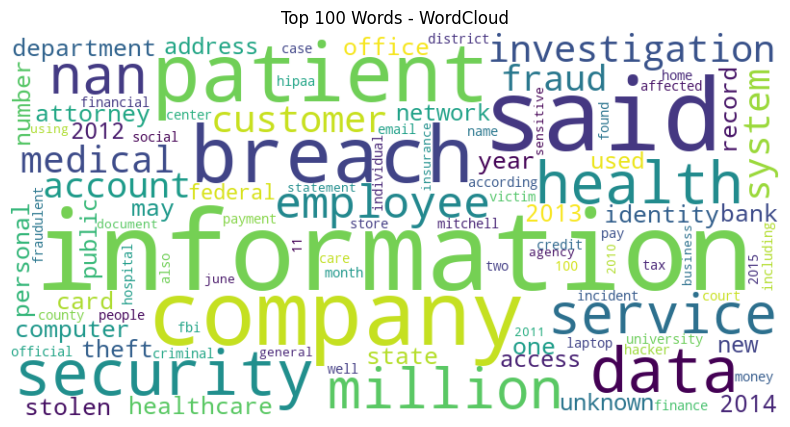

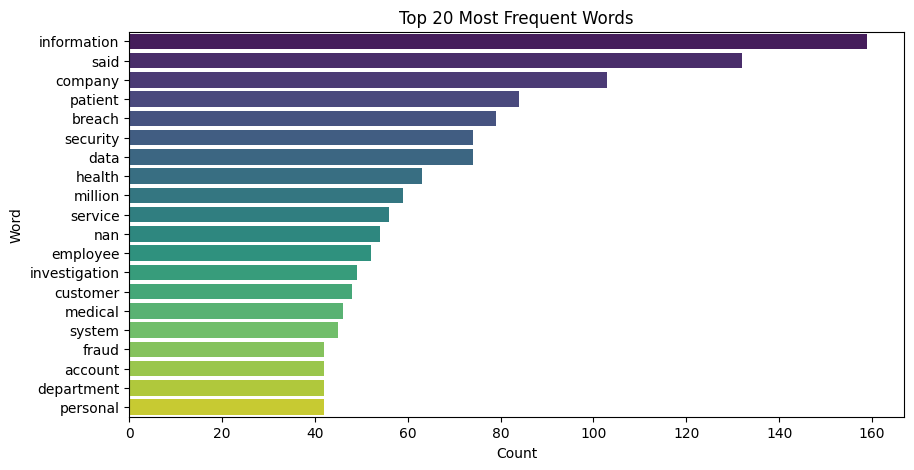

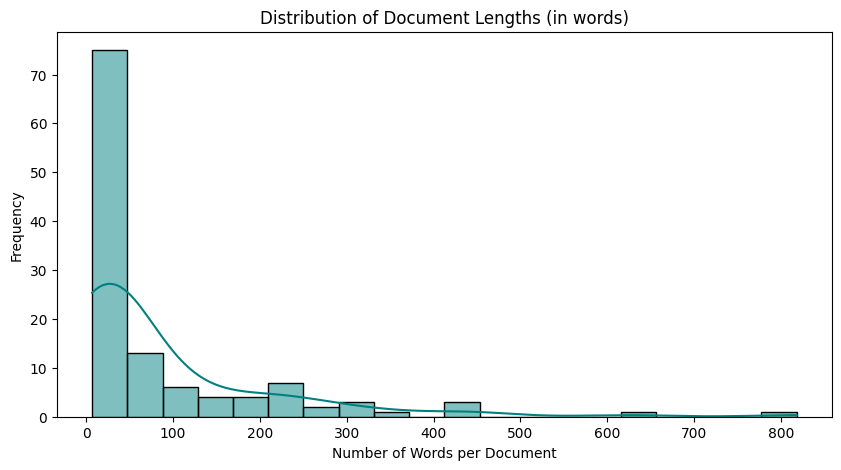

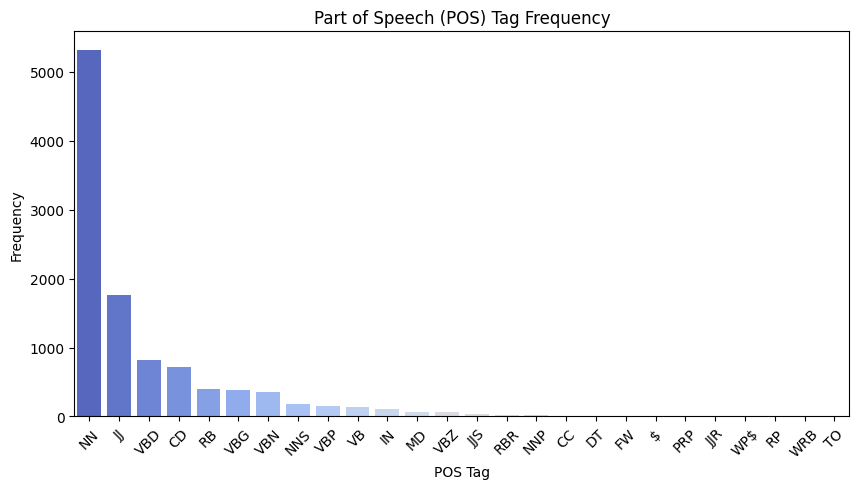

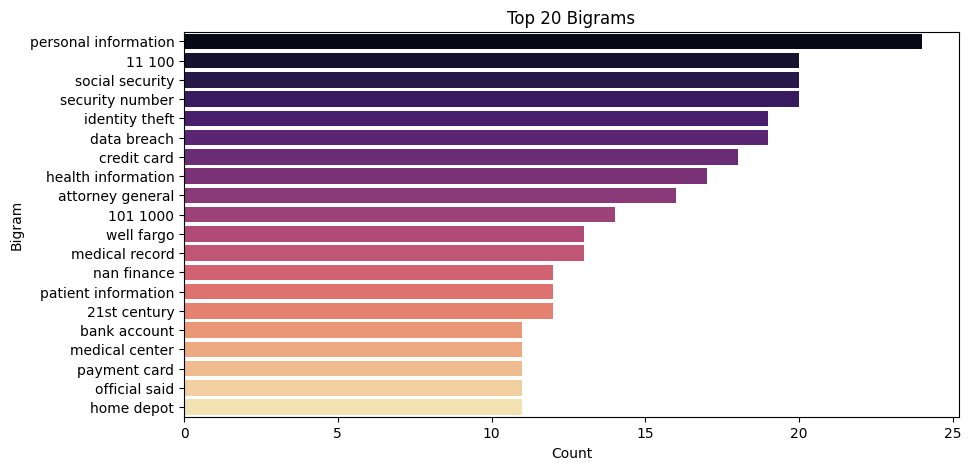

In [15]:
import warnings
warnings.filterwarnings("ignore")

eda_nlp_analysis()

# Tramsformer Driven Feature Extraction

In [16]:
def Transformer_feature_extraction(
        texts,
        model_name,
        batch_size=32,
        pooling='cls',  # or 'mean'
        device=None):

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    
    model.eval()
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    all_embs = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Extracting Trasformer embeddings"):
        batch = texts[i:i+batch_size]
        enc = tokenizer(batch, padding=True, truncation=True, return_tensors='pt')
        enc = {k: v.to(device) for k, v in enc.items()}

        with torch.no_grad():
            output = model(**enc)

        # output.last_hidden_state: sequence of hidden states for each character’s embedding after upsampling
        # output.pooler_output: the pooled [CLS]-style output (for classification / sentence-level features)
        if pooling == 'cls':
            embs = output.pooler_output
        elif pooling == 'mean':
            # mean over sequence dimension
            embs = output.last_hidden_state.mean(dim=1)
        else:
            raise ValueError("pooling must be 'cls' or 'mean'")

        all_embs.append(embs.cpu().numpy())

    X = np.vstack(all_embs)
    return X, model

In [17]:
def feature_extraction(X_text, method='Transfoermer_Embeddings', model_dir='model', is_train=True):
    x_file = os.path.join(model_dir, f'X_{method}.pkl')

    print( f"[INFO] Feature extraction method: {method}, Train mode: {is_train}"+"\n\n")
    model_name='sentence-transformers/all-MiniLM-L6-v2'

    if is_train:
        if os.path.exists(x_file):
            print(f"[INFO] Loading cached embeddings from {x_file}"+"\n\n")
            X = joblib.load(x_file)
        else:
            print( "[INFO] Computing embeddings..."+"\n\n")
            X, model = Transformer_feature_extraction(X_text, model_name=model_name, pooling='mean')
            os.makedirs(model_dir, exist_ok=True)
            joblib.dump(X, x_file)
    else:
        print( "[INFO] Performing embedding extraction for testing..."+"\n\n")
        X, model = Transformer_feature_extraction(X_text, model_name=model_name, pooling='mean')

    return X

In [18]:
def feature_extraction_button():
    global X, features
    global features_dict, labels_dict, target_cols

    from imblearn.over_sampling import SMOTE, RandomOverSampler
    # ---------------- FEATURE EXTRACTION ----------------
    features = feature_extraction( X, method='Transfoermer_Embeddings', model_dir=MODEL_DIR, is_train=True)

    original_features = {}
    original_labels = {}

    for i, (key, y) in enumerate(Y_dict.items(), start=1):

        print(f"\n🔹 Processing '{key}' (Original)...\n")

        original_features[f'features{i}'] = features
        original_labels[f'Y{i}'] = y

        print(
            f"Dataset: features{i}.shape = {features.shape}, "
            f"Y{i}.shape = {y.shape}\n"
        )

    # ---------------- BALANCING ----------------
    resampled_features = {}
    resampled_labels = {}

    target_names = target_cols

    for idx, name in enumerate(target_names, start=1):

        X_target = original_features[f'features{idx}']
        y_target = original_labels[f'Y{idx}']

        # -------- Before Sampling --------
        classes_before, counts_before = np.unique(y_target,return_counts=True)
        
        min_class_count = np.min(counts_before)

        try:
            # Use RandomOverSampler when any class has < 6 samples
            if min_class_count < 6:

                sampler = RandomOverSampler(random_state=42)
                sampler_name = "RandomOverSampler"
            else:
                sampler = SMOTE(random_state=42)
                sampler_name = "SMOTE"

            X_res, y_res = sampler.fit_resample(X_target,y_target)

        except Exception as e:

            print(
                f"Sampling Failed for {name}: {str(e)}\n"
                f"Original data retained.\n"
            )

            X_res = X_target
            y_res = y_target
            sampler_name = "None"

        # -------- After Sampling --------
        classes_after, counts_after = np.unique(
            y_res,
            return_counts=True
        )

        resampled_features[name] = X_res
        resampled_labels[name] = y_res

        print(f"{sampler_name} Applied for {name}:")

        print(f"Before: {dict(zip(classes_before, counts_before))}")

        print(f"After : {dict(zip(classes_after, counts_after))}")

        print( f"New shape: {X_res.shape}, {y_res.shape}\n")

        # -------- Bar Graph --------
        plt.figure(figsize=(8, 5))

        x_before = np.arange(len(classes_before))
        x_after = np.arange(len(classes_after))

        plt.bar(
            x_before - 0.2,
            counts_before,
            width=0.4,
            label="Before Sampling"
        )

        plt.bar(
            x_after + 0.2,
            counts_after,
            width=0.4,
            label="After Sampling"
        )

        plt.xticks(x_before, classes_before)
        plt.xlabel("Class Labels")
        plt.ylabel("Number of Samples")
        plt.title(
            f"{name}: Before vs After {sampler_name}"
        )
        plt.legend()
        plt.tight_layout()
        plt.show()

    # ---------------- SAVE RESULTS ----------------
    features_dict = resampled_features
    labels_dict = resampled_labels
    print("\nFeature Extraction + Class Balancing Completed Successfully\n")

    #  Summary
    print("Balanced Dataset Summary:\n")
    for key in labels_dict:
        classes, counts = np.unique(labels_dict[key],return_counts=True)
        print( f"{key}: {dict(zip(classes, counts))}")

[INFO] Feature extraction method: Transfoermer_Embeddings, Train mode: True


[INFO] Loading cached embeddings from DNN_model\X_Transfoermer_Embeddings.pkl



🔹 Processing 'pattern' (Original)...

Dataset: features1.shape = (120, 384), Y1.shape = (120,)


🔹 Processing 'Actor' (Original)...

Dataset: features2.shape = (120, 384), Y2.shape = (120,)

SMOTE Applied for pattern:
Before: {0: 18, 1: 13, 2: 12, 3: 15, 4: 32, 5: 15, 6: 15}
After : {0: 32, 1: 32, 2: 32, 3: 32, 4: 32, 5: 32, 6: 32}
New shape: (224, 384), (224,)



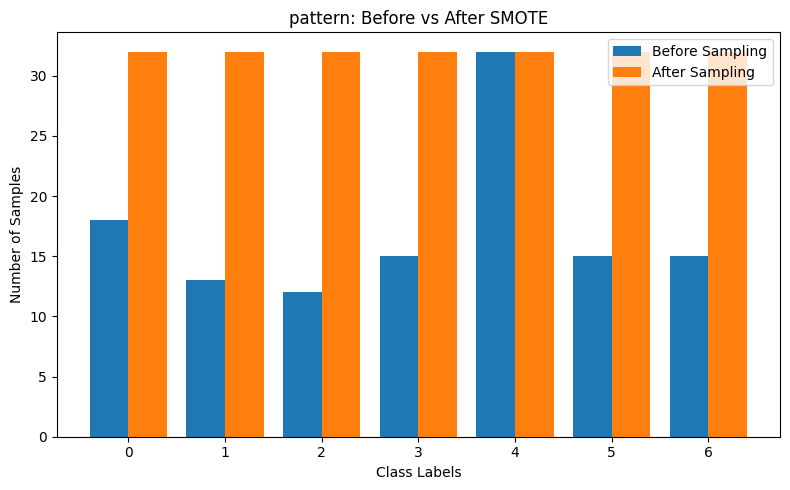

RandomOverSampler Applied for Actor:
Before: {0: 69, 1: 40, 2: 7, 3: 4}
After : {0: 69, 1: 69, 2: 69, 3: 69}
New shape: (276, 384), (276,)



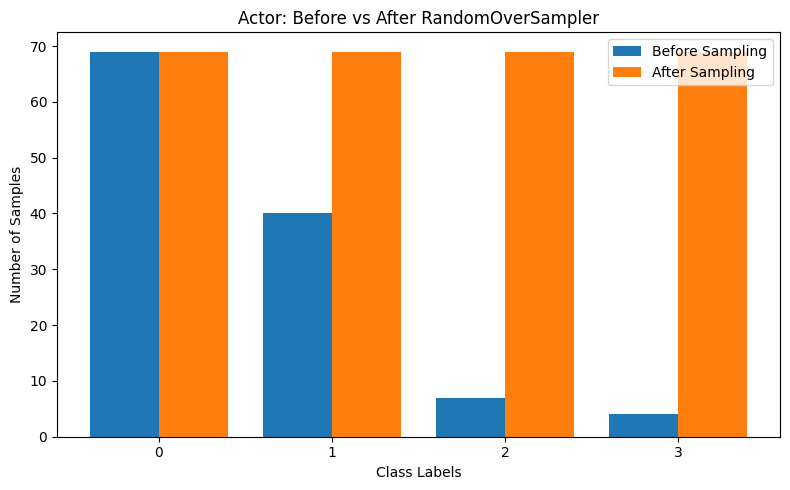


Feature Extraction + Class Balancing Completed Successfully

Balanced Dataset Summary:

pattern: {0: 32, 1: 32, 2: 32, 3: 32, 4: 32, 5: 32, 6: 32}
Actor: {0: 69, 1: 69, 2: 69, 3: 69}


In [19]:
feature_extraction_button()

# Existing and Proposed Classifiers

In [20]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imodels import BoostedRulesClassifier
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier

from imodels import BoostedRulesClassifier, FIGSClassifier

def train_ml_models(Algorithm_prefix, features_dict, Y_dict, algorithm):
    ml_models = {}

    model_mapping = {
        "LR": LogisticRegression,
        "ETC": ExtraTreesClassifier,
        "DTC": DecisionTreeClassifier,
        "BRC": BoostedRulesClassifier,
        "Proposed": RandomForestClassifier
    }

    if algorithm not in model_mapping:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    for target_name, y_encoded in Y_dict.items():

        X = features_dict[target_name]
        model_cls = model_mapping[algorithm]

        model_path = f"{MODEL_DIR}/Transformer_Embeddings_{target_name}_{algorithm}_model.pkl"
        algo_name = f"{Algorithm_prefix} {algorithm} [{target_name}]"

        X_train, X_test, y_train, y_test = train_test_split( X,y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

        # ---------------- MODEL INITIALIZATION ----------------
        if algorithm == "LR":
            mdl = model_cls(max_iter=50, C=0.1, solver='liblinear')

        elif algorithm == "ETC":
            mdl = model_cls(n_estimators=10, max_depth=5, min_samples_split=10, min_samples_leaf=5)

        elif algorithm == "DTC":
            mdl = model_cls(max_depth=3, min_samples_split=10, min_samples_leaf=5)

        elif algorithm == "BRC":
            mdl = model_cls()

        elif algorithm == "Proposed":
            mdl = model_cls()

        # ---------------- LOAD OR TRAIN ----------------
        if os.path.exists(model_path):
            print(f"[LOAD] Existing {algorithm} model for: {target_name}")
            mdl = joblib.load(model_path)
        else:
            print(f"[TRAIN] {algorithm} model → Target: {target_name}")
            mdl.fit(X_train, y_train)
            joblib.dump(mdl, model_path, compress=("lzma", 3))

        # ---------------- PREDICTION ----------------
        y_pred = mdl.predict(X_test)

        try:
            y_score = mdl.predict_proba(X_test)
        except:
            y_score = None

        # ---------------- METRICS ----------------
        if target_name in metrics_calculator_dict:
            metrics_calculator_dict[target_name].calculate_metrics( algo_name, y_pred, y_test, y_score)
        ml_models[f"{target_name}_{algorithm}"] = mdl

    return ml_models

In [21]:
def existing_classifier1():
   
    global features_dict,labels_dict
    models = train_ml_models("Transformer_Embeddings", features_dict, labels_dict, "LR")

[LOAD] Existing LR model for: pattern
Transformer_Embeddings LR [pattern] Accuracy  : 80.0000

Transformer_Embeddings LR [pattern] Precision : 81.7517

Transformer_Embeddings LR [pattern] Recall    : 80.6122

Transformer_Embeddings LR [pattern] FScore    : 79.5419




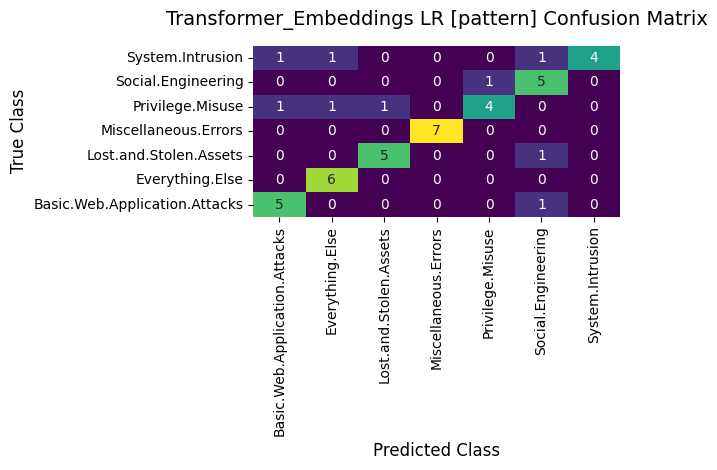

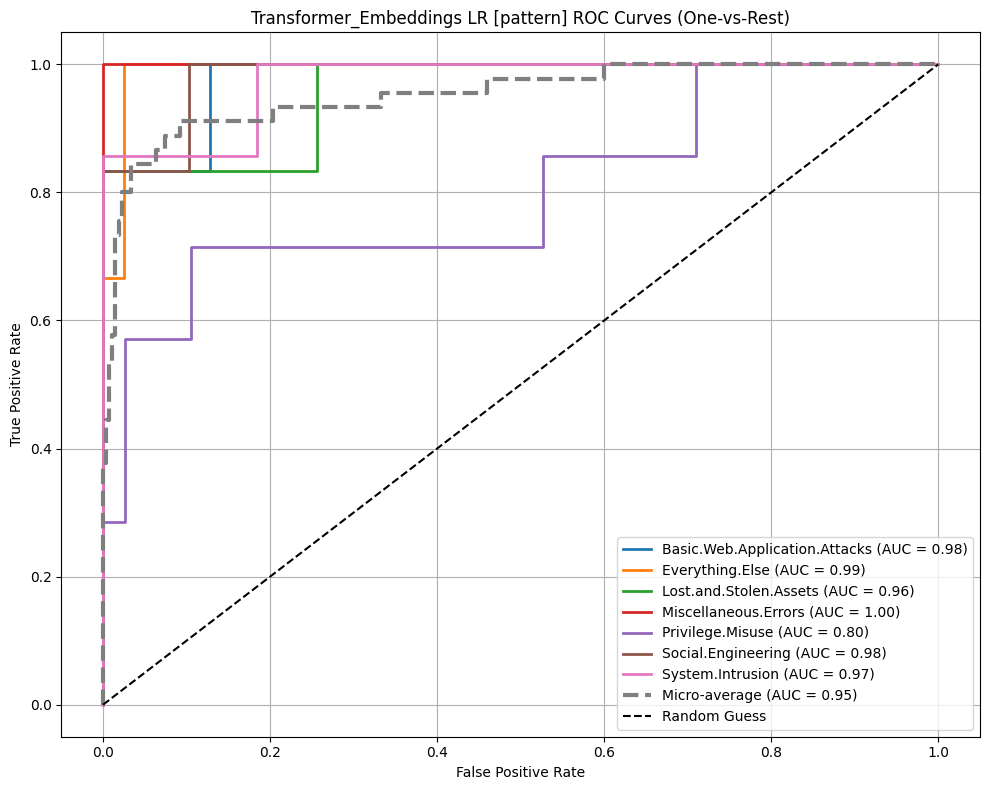

[LOAD] Existing LR model for: Actor
Transformer_Embeddings LR [Actor] Accuracy  : 87.5000

Transformer_Embeddings LR [Actor] Precision : 87.0513

Transformer_Embeddings LR [Actor] Recall    : 87.5000

Transformer_Embeddings LR [Actor] FScore    : 87.1648




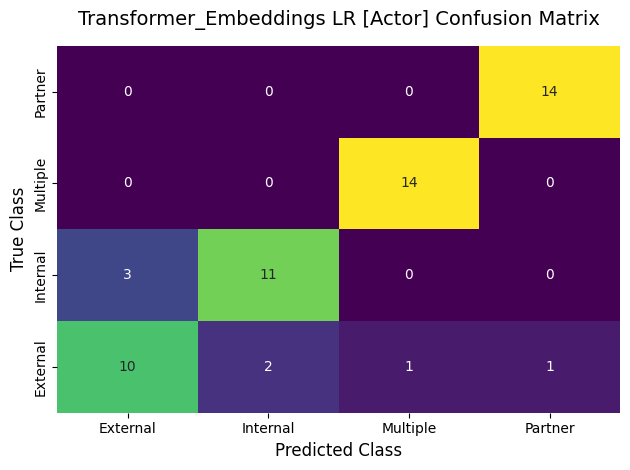

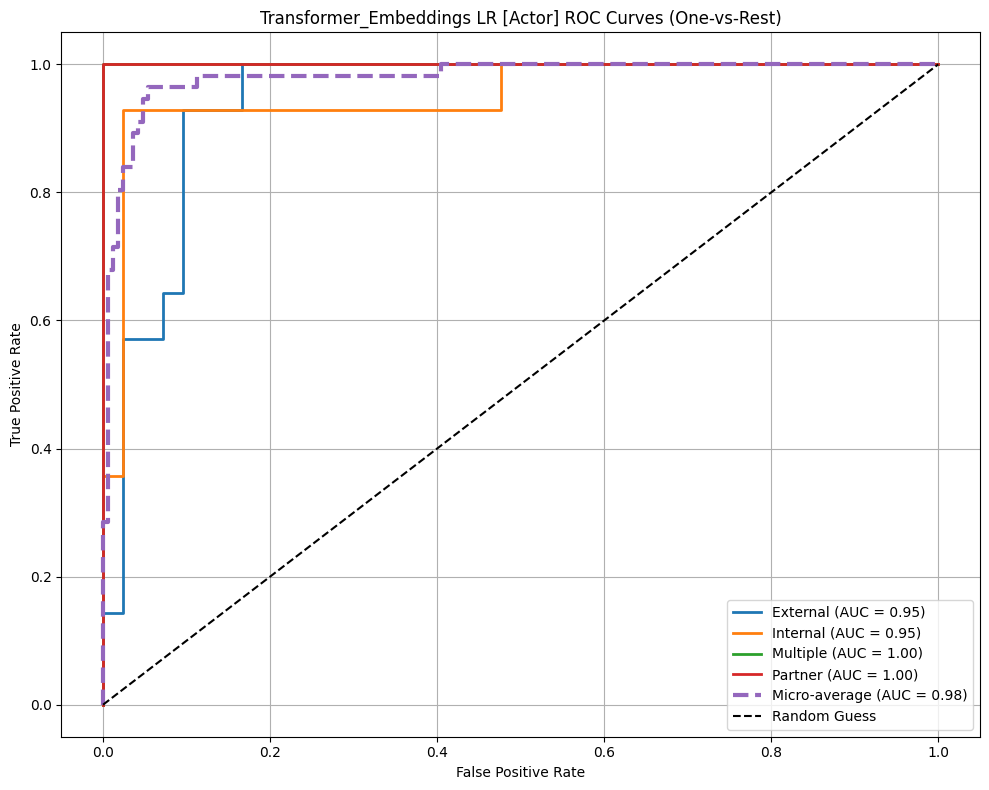

In [22]:
import warnings
warnings.filterwarnings("ignore")
existing_classifier1()

[LOAD] Existing ETC model for: pattern
Transformer_Embeddings ETC [pattern] Accuracy  : 75.5556

Transformer_Embeddings ETC [pattern] Precision : 75.5952

Transformer_Embeddings ETC [pattern] Recall    : 76.8707

Transformer_Embeddings ETC [pattern] FScore    : 74.6311




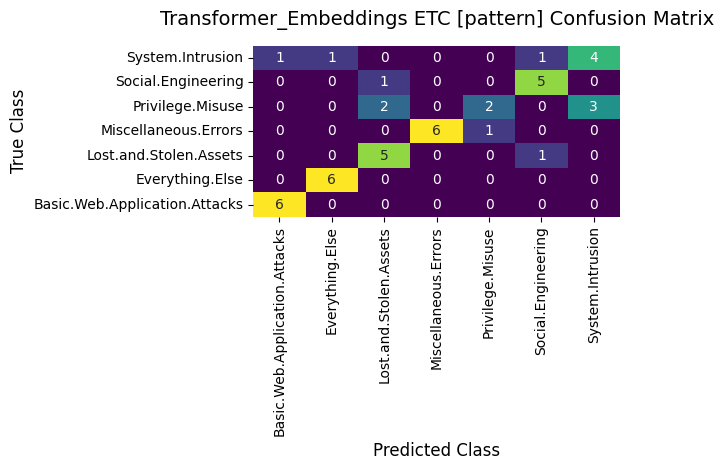

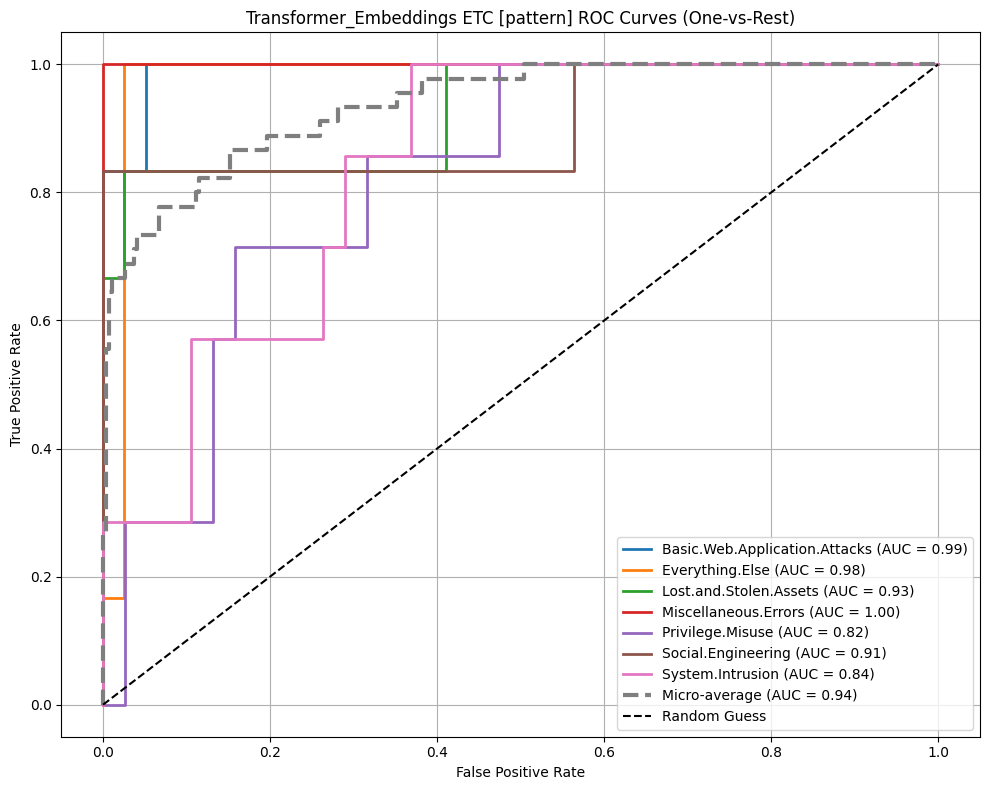

[LOAD] Existing ETC model for: Actor
Transformer_Embeddings ETC [Actor] Accuracy  : 87.5000

Transformer_Embeddings ETC [Actor] Precision : 88.6111

Transformer_Embeddings ETC [Actor] Recall    : 87.5000

Transformer_Embeddings ETC [Actor] FScore    : 86.8417




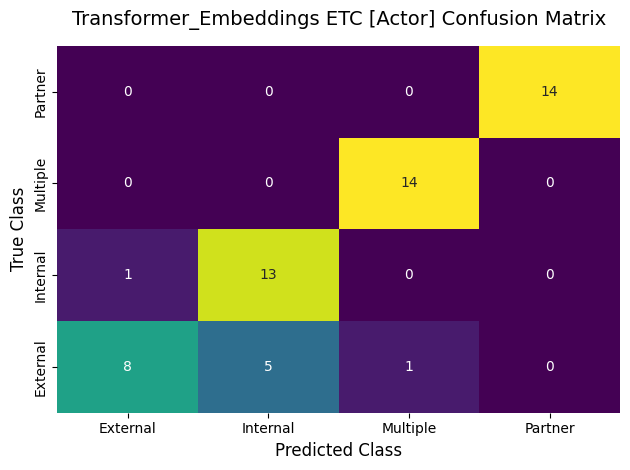

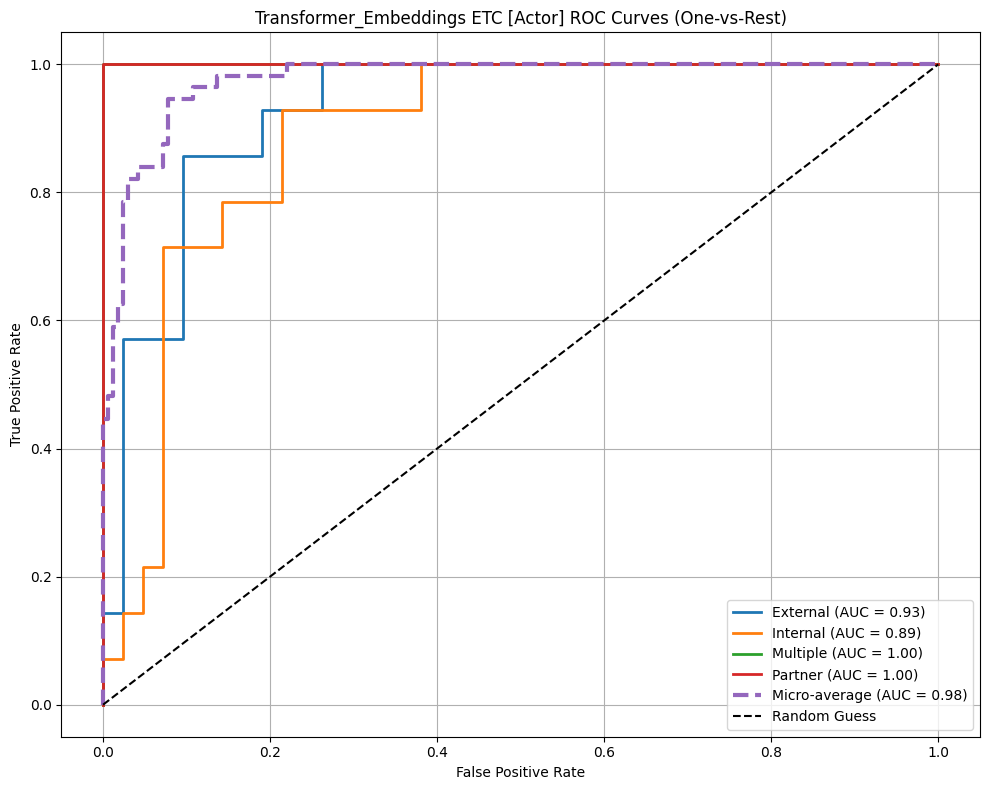

In [23]:
def existing_classifier2():

    global features_dict,labels_dict
    models = train_ml_models("Transformer_Embeddings", features_dict, labels_dict, "ETC")
existing_classifier2()

# DNN Feature Selection

In [24]:
def plot_training_history(history):
    
    plt.figure(figsize=(12, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Val Accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

def train_DNN_feature_selection(X, y,DENSE_MODEL_PATH, FEATURE_PATH, HISTORY_PATH):

    if all(os.path.exists(p) for p in [DENSE_MODEL_PATH, FEATURE_PATH, HISTORY_PATH]):
        print("✅ [LOAD] Model and features found. Loading...")
        model = load_model(DENSE_MODEL_PATH)
        features = np.load(FEATURE_PATH)
        history = np.load(HISTORY_PATH, allow_pickle=True).item()
        return features

    print("🚀 [TRAIN] No saved model found. Training new Dense model...")


    
    # Use existing encoded labels
    num_classes = len(np.unique(y))
    y_categorical = to_categorical(y, num_classes=num_classes)

    # Build deeper model
    input_layer = Input(shape=(X.shape[1],))
    x = Dense(512, activation='relu')(input_layer)
    x = Dense(256, activation='relu')(x)
    x = Dense(128, activation='relu', name='feature_layer')(x)
    x = Dense(64, activation='relu')(x)
    output_layer = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Train model
    history = model.fit(
        X, y_categorical,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    # Extract mid-layer features
    feature_extractor = Model(inputs=model.input, outputs=model.get_layer('feature_layer').output)
    features = feature_extractor.predict(X)

    # Save everything
    model.save(DENSE_MODEL_PATH)
    np.save(FEATURE_PATH, features)
    np.save(HISTORY_PATH, history.history)

    print("💾 Model, features, labels, and training history saved.")


    return features

def DNN_feature_selection():
    global features_dict,labels_dict
    Y_dict = labels_dict
    global dnn_features_dict, dnn_labels_dict
    

    dnn_features_dict = {}
    dnn_labels_dict = {}

    for target_name, y_encoded in Y_dict.items():

        # input features per target
        X = features_dict[target_name]

        print(f"[DNN] Feature selection → Target: {target_name}\n")

        # target-wise save paths
        DENSE_MODEL_PATH = os.path.join(
            MODEL_DIR, f"dense_feature_model_{target_name}.h5"
        )
        HISTORY_PATH = os.path.join(
            MODEL_DIR, f"history_{target_name}.npy"
        )
        FEATURE_PATH = os.path.join(MODEL_DIR, f"extracted_features__{target_name}.npy")


        # train DNN + extract features
        selected_features = train_DNN_feature_selection(
            X, y_encoded,DENSE_MODEL_PATH, FEATURE_PATH, HISTORY_PATH
        )


        # store results
        dnn_features_dict[target_name] = selected_features
        dnn_labels_dict[target_name] = y_encoded

    print("\n[DNN] Feature selection completed for all targets\n")

In [25]:
DNN_feature_selection()

[DNN] Feature selection → Target: pattern

✅ [LOAD] Model and features found. Loading...
[DNN] Feature selection → Target: Actor

✅ [LOAD] Model and features found. Loading...



[DNN] Feature selection completed for all targets



[LOAD] Existing Proposed model for: pattern
Transformer_Embeddings Proposed [pattern] Accuracy  : 100.0000

Transformer_Embeddings Proposed [pattern] Precision : 100.0000

Transformer_Embeddings Proposed [pattern] Recall    : 100.0000

Transformer_Embeddings Proposed [pattern] FScore    : 100.0000




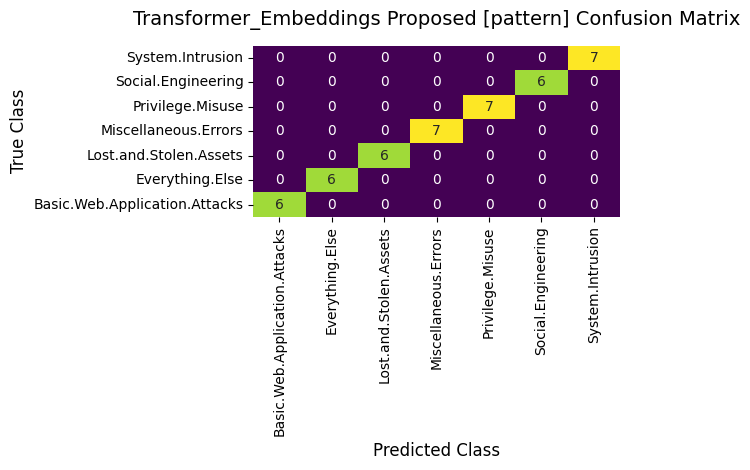

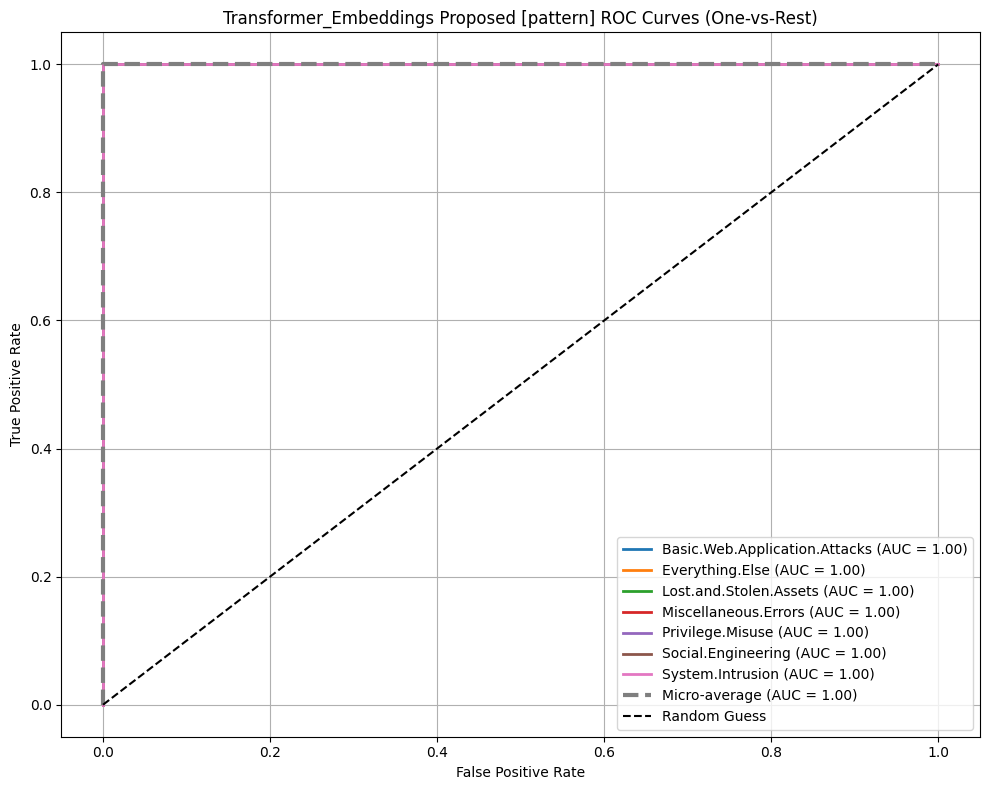

[LOAD] Existing Proposed model for: Actor
Transformer_Embeddings Proposed [Actor] Accuracy  : 100.0000

Transformer_Embeddings Proposed [Actor] Precision : 100.0000

Transformer_Embeddings Proposed [Actor] Recall    : 100.0000

Transformer_Embeddings Proposed [Actor] FScore    : 100.0000




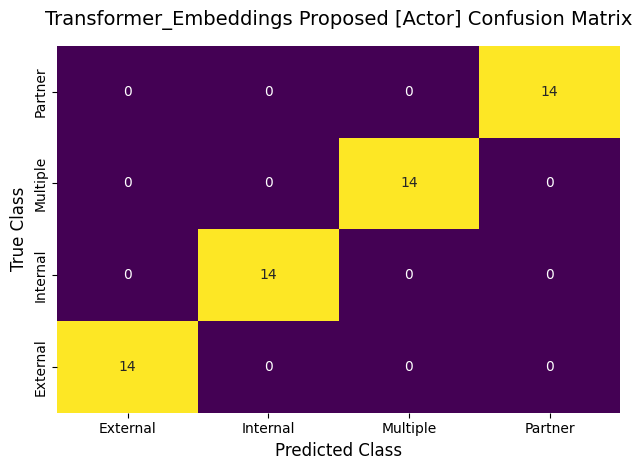

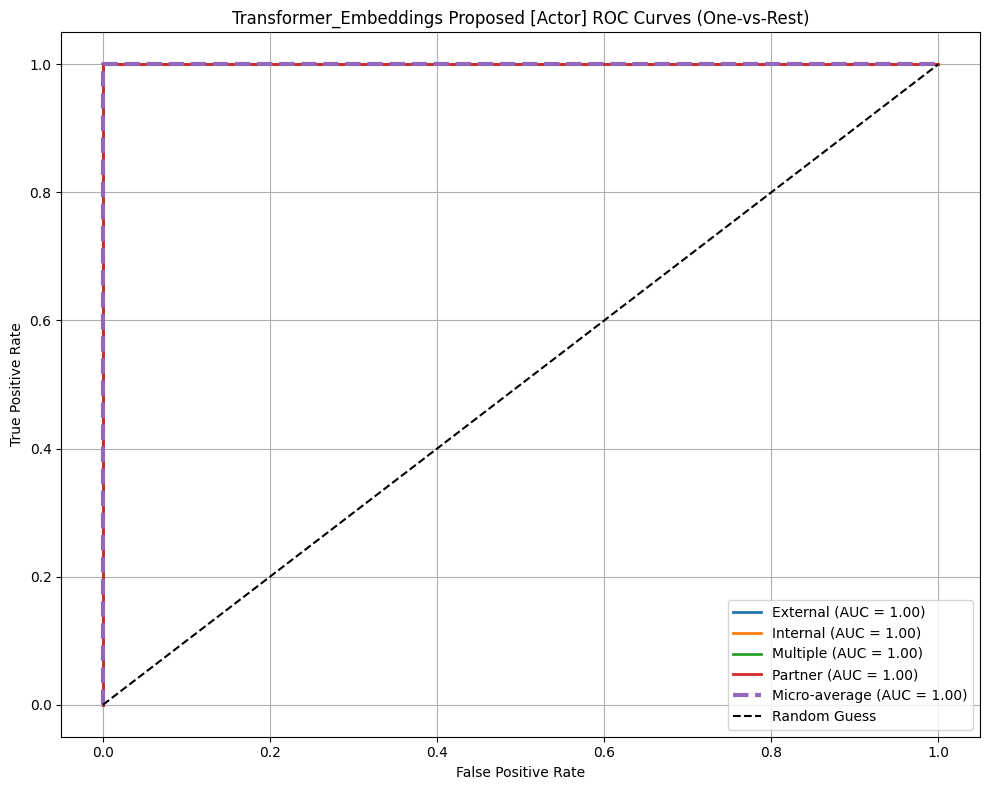

In [26]:
def Proposed_classifier():

    global features_dict,labels_dict
    models = train_ml_models("Transformer_Embeddings", dnn_features_dict, dnn_labels_dict, "Proposed")
Proposed_classifier()

In [27]:
def graph():

    for target_name, calculator in metrics_calculator_dict.items():

        if calculator.metrics_df.empty:
            print(f"No metrics found for {target_name}\n")
            continue

        # Copy main table
        df_h = calculator.metrics_df[['Algorithm', 'Accuracy', 'Precision', 'Recall', 'F1-Score']].copy()
        df_h = df_h.round(3)

        first_alg = df_h['Algorithm'].iloc[0]
        detected_name = re.search(r'\[(.*?)\]', first_alg)

        if detected_name:
            extracted_target = detected_name.group(1)
        else:
            extracted_target = target_name

        print(f"\n=== Performance for {extracted_target} ===\n")

        df_h['Algorithm'] = df_h['Algorithm'].str.replace(
            r'\s*\[.*?\]', '', regex=True
        )

        print(df_h.to_string(index=False))
        print("\n")

In [28]:
graph()


=== Performance for pattern ===

                      Algorithm  Accuracy  Precision  Recall  F1-Score
      Transformer_Embeddings LR    80.000     81.752  80.612    79.542
     Transformer_Embeddings ETC    75.556     75.595  76.871    74.631
Transformer_Embeddings Proposed   100.000    100.000 100.000   100.000



=== Performance for Actor ===

                      Algorithm  Accuracy  Precision  Recall  F1-Score
      Transformer_Embeddings LR      87.5     87.051    87.5    87.165
     Transformer_Embeddings ETC      87.5     88.611    87.5    86.842
Transformer_Embeddings Proposed     100.0    100.000   100.0   100.000




# Prediction

In [29]:
def test_extract_features_from_dense_model(X_test, model_path="dense_feature_model.h5"):
    print(f"✅ Loading model from: {model_path}")
    model = load_model(model_path)

    # Extract output from the intermediate 'feature_layer'
    feature_extractor = Model(inputs=model.input,
                              outputs=model.get_layer("feature_layer").output)

    print("🚀 Extracting features from test data...")
    features_test = feature_extractor.predict(X_test)

    return features_test

In [30]:
def Prediction():

    import re
    import joblib
    import numpy as np
    import pandas as pd
    from pathlib import Path

    global df_result

    # ---------------- LOAD TEST DATA ----------------
    test_filename = r"C:\Users\ADVAITHA-AI\Desktop\Cyber insurance code\Dataset\Test.csv"

    df_test1 = pd.read_csv(test_filename)
    df_result = df_test1.copy()

    print(f"\nLoaded Test File: {test_filename}")
    print(f"Total Test Samples: {len(df_test1)}")

    # ---------------- PREPROCESS ----------------
    print("\nPreprocessing test data...")
    df_test, _ = preprocess_data(df_test1)

    # ---------------- FEATURE EXTRACTION ----------------
    print("\nExtracting Transformer embeddings...")

    base_features_test = feature_extraction(
        df_test,
        method='Transformer_Embeddings',
        is_train=False
    )

    # ---------------- MODEL DIRECTORY ----------------
    model_dir = Path(MODEL_DIR)

    if not model_dir.exists():
        print(f"\nModel directory not found: {model_dir}")
        return

    # ---------------- FIND MODELS ----------------
    model_files = list(
        model_dir.glob(
            "Transformer_Embeddings_*_Proposed_model.pkl"
        )
    )

    if len(model_files) == 0:
        print("\nNo proposed models found.")
        return

    print(f"\nFound {len(model_files)} proposed models")

    # ---------------- PREDICTION ----------------
    for model_file in model_files:

        match = re.search(
            r"Transformer_Embeddings_(.*?)_Proposed_model\.pkl",
            model_file.name
        )

        if not match:
            continue

        target_name = match.group(1).strip()

        print("\n" + "=" * 60)
        print(f"Loading Proposed Model : {target_name}")
        print("=" * 60)

        DENSE_MODEL_PATH = model_dir / f"dense_feature_model_{target_name}.h5"
        if not DENSE_MODEL_PATH.exists():
            text.insert(
                END,
                f" DNN model not found for {target_name}, using base features\n"
            )
            features_test = base_features_test
        else:
            features_test = test_extract_features_from_dense_model(
                base_features_test,
                str(DENSE_MODEL_PATH)
            )

        
        label_file = model_dir / f"labels_{target_name}.npy"

        if not label_file.exists():
            print(f"Labels file not found: {label_file}")
            continue

        try:
            labels = np.load(
                label_file,
                allow_pickle=True
            )

            model = joblib.load(model_file)

            y_pred = model.predict(features_test)

            mapped = [labels[int(i)] for i in y_pred]

            pred_col = f"Predicted_{target_name}"

            df_result[pred_col] = mapped

            print(f"Prediction completed for {target_name}")

        except Exception as e:
            print(f"Error in {target_name}: {str(e)}")

    # ---------------- DISPLAY RESULTS ----------------
    pred_cols = [
        c for c in df_result.columns
        if c.startswith("Predicted_")
    ]

    print("\n")
    print("=" * 80)
    print("PREDICTION RESULTS")
    print("=" * 80)

    for i, row in df_result.iterrows():

        print(f"\nRow {i + 1}")
        print("-" * 50)

        for col in df_result.columns:

            if col not in pred_cols:
                print(f"{col}: {row[col]}")

        print("\nPredictions:")
        for col in pred_cols:
            print(f"{col}: {row[col]}")

    print("\nPrediction completed successfully.")

    return df_result

In [31]:
Prediction()


Loaded Test File: C:\Users\ADVAITHA-AI\Desktop\Cyber insurance code\Dataset\Test.csv
Total Test Samples: 16

Preprocessing test data...
Preprocessing data (no saving)


100%|████████████████████████████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 6247.92it/s]

100%|████████████████████████████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 5559.51it/s]

Processing Text Columns: 100%|███████████████████████████████████████████████████████| 4/4 [00:04<00:00,  1.10s/column]



Extracting Transformer embeddings...
[INFO] Feature extraction method: Transformer_Embeddings, Train mode: False


[INFO] Performing embedding extraction for testing...




Extracting Trasformer embeddings: 100%|██████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.58s/it]



Found 2 proposed models

Loading Proposed Model : Actor
✅ Loading model from: DNN_model\dense_feature_model_Actor.h5
🚀 Extracting features from test data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step


Prediction completed for Actor

Loading Proposed Model : pattern
✅ Loading model from: DNN_model\dense_feature_model_pattern.h5
🚀 Extracting features from test data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
Prediction completed for pattern


PREDICTION RESULTS

Row 1
--------------------------------------------------
ID: 137
year: 2015
victim.victim_id: American Tooling Center
org_size: 11 - 100
pattern: Social.Engineering
summary: a federal appeals court has sided with a commercial policyholder where the insurer denied coverage under a computer fraud provision of a crime insurance policy for a money transfer involving fraudulent emails.  The Sixth Circuit appeals court found that Travelers was wrong to deny the claim of American Tooling Center, a Michigan tool-and-die company that wired $800,000 in funds to a fraudster’s account in the belief the account belonged to one of its Chinese subcontractors.

Predictions:
Predicted_Actor: External
Predicted_pattern: Social.Engineering

Row 2
-

,ID,year,victim.victim_id,org_size,pattern,summary,Predicted_Actor,Predicted_pattern
0,137,2015,American Tooling Center,11 - 100,Social.Engineering,a federal appeals court has sided with a comme...,External,Social.Engineering
1,158,2015,Ubiquiti Networks Inc.,101 - 1000,Social.Engineering,"Ubiquiti Networks Inc., the San Jose based man...",External,Social.Engineering
2,88,2013,University of Mississippi Medical Center,"1,001 - 10,000",Lost.and.Stolen.Assets,The University of Mississippi Medical Center i...,External,Lost.and.Stolen.Assets
3,94,2013,Wells Fargo,"Over 100,000",Privilege.Misuse,former fire captain accessed the account of a ...,Internal,Privilege.Misuse
4,177,2016,Platte County Assessor Office,11 - 100,Social.Engineering,transferred money on spoofed email from CEO,External,Social.Engineering
5,202,2018,Oregon Department of Revenue,"1,001 - 10,000",Privilege.Misuse,employee copies spreadsheets to personal googl...,Internal,Privilege.Misuse
6,101,2013,Broward County Court,Unknown,Privilege.Misuse,A Broward County court clerk on Monday joined ...,Internal,Privilege.Misuse
7,121,2014,Inputs.io,1 to 10,Basic.Web.Application.Attacks,Inputs.io has been hacked with total of 4100 B...,External,Basic.Web.Application.Attacks
8,70,2013,Hospice of North Idaho,11 - 100,Lost.and.Stolen.Assets,The June 2010 theft of an unencrypted laptop f...,External,Lost.and.Stolen.Assets
9,102,2013,Valley National Bancorp,"1,001 - 10,000",Everything.Else,ATM skimming leads to loss of payment card inf...,External,Everything.Else


In [32]:
df_result

,ID,year,victim.victim_id,org_size,pattern,summary,Predicted_Actor,Predicted_pattern
0,137,2015,American Tooling Center,11 - 100,Social.Engineering,a federal appeals court has sided with a comme...,External,Social.Engineering
1,158,2015,Ubiquiti Networks Inc.,101 - 1000,Social.Engineering,"Ubiquiti Networks Inc., the San Jose based man...",External,Social.Engineering
2,88,2013,University of Mississippi Medical Center,"1,001 - 10,000",Lost.and.Stolen.Assets,The University of Mississippi Medical Center i...,External,Lost.and.Stolen.Assets
3,94,2013,Wells Fargo,"Over 100,000",Privilege.Misuse,former fire captain accessed the account of a ...,Internal,Privilege.Misuse
4,177,2016,Platte County Assessor Office,11 - 100,Social.Engineering,transferred money on spoofed email from CEO,External,Social.Engineering
5,202,2018,Oregon Department of Revenue,"1,001 - 10,000",Privilege.Misuse,employee copies spreadsheets to personal googl...,Internal,Privilege.Misuse
6,101,2013,Broward County Court,Unknown,Privilege.Misuse,A Broward County court clerk on Monday joined ...,Internal,Privilege.Misuse
7,121,2014,Inputs.io,1 to 10,Basic.Web.Application.Attacks,Inputs.io has been hacked with total of 4100 B...,External,Basic.Web.Application.Attacks
8,70,2013,Hospice of North Idaho,11 - 100,Lost.and.Stolen.Assets,The June 2010 theft of an unencrypted laptop f...,External,Lost.and.Stolen.Assets
9,102,2013,Valley National Bancorp,"1,001 - 10,000",Everything.Else,ATM skimming leads to loss of payment card inf...,External,Everything.Else
